### Описание задачи
* Анализ влияния личностных черт (Big Five / OCEAN) и социально-демографических факторов на уровень дохода (на примере датасета Big Five Personality & Life Outcomes).
* **Тип задачи:** Бинарная классификация ($K = 2$).
* **Целевая переменная ($y$):** `high_income` (1 — высокий доход, 0 — обычный/низкий доход).
* **Признаки ($X$):** 21 признак, включающий психологические черты личности по модели Большой пятерки (Openness, Conscientiousness, Extraversion, Agreeableness, Neuroticism), возраст, пол, уровень образования, GPA, показатель когнитивных способностей, вредные привычки и другие показатели. Служебный идентификатор `person_id` исключается из обучения.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Читаем датасет
df = pd.read_csv(filename)
print(f"Размер: {df.shape}")
# первые 5 строк
display(df.head())

print("\n--- Общая информация ---")
print(f"Размер датасета (объектов, признаков): {df.shape}")
print(f"Колонок всего: {df.shape[1]}")

# Исключаем person_id из признаков, так как это просто уникальный индекс
if 'person_id' in df.columns:
    df = df.drop(columns=['person_id'])
    print("\nСтолбец 'person_id' исключен.")

Saving big_five_life_outcomes (2).csv to big_five_life_outcomes (2) (1).csv
Успешно загружено! Размер: (50000, 23)


,person_id,age,sex,openness,conscientiousness,extraversion,agreeableness,neuroticism,parental_ses,parental_education_years,...,gpa,job_performance,income_usd,life_satisfaction,exercise_days_week,smoker,self_rated_health,partnered,ever_divorced,high_income
0,PSN000000,18,F,51.7,37.3,63.0,77.5,43.9,76.2,14,...,3.68,3.87,77200.0,8.8,2,1,3.83,0,0,1
1,PSN000001,50,M,26.2,74.4,28.4,60.6,88.6,47.3,13,...,2.81,2.17,46200.0,4.0,2,0,3.03,1,0,0
2,PSN000002,40,F,69.4,53.4,22.1,37.7,18.0,45.2,13,...,2.48,2.18,32800.0,5.9,5,0,3.70,1,0,0
3,PSN000003,18,F,62.5,56.5,12.9,27.8,26.6,29.9,8,...,2.71,1.80,33100.0,8.5,0,0,2.46,0,0,0
4,PSN000004,35,F,40.1,62.8,38.6,73.8,31.7,15.2,8,...,2.06,2.46,55200.0,6.1,3,0,3.23,0,0,0



--- Общая информация ---
Размер датасета (объектов, признаков): (50000, 23)
Колонок всего: 23

Служебный столбец 'person_id' успешно исключен.


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['person_id', 'high_income'], errors='ignore')
y = df['high_income']

if 'sex' in X.columns and X['sex'].dtype == 'object':
    X = pd.get_dummies(X, columns=['sex'], drop_first=True, dtype=int)

#Делим данные на обучающую (80%) и тестовую (20%) выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Размер обучающей выборки (X_train): {X_train.shape}")
print(f"Размер тестовой выборки (X_test): {X_test.shape}")

Категориальный признак 'sex' успешно закодирован (One-Hot Encoding).
Размер обучающей выборки (X_train): (40000, 21)
Размер тестовой выборки (X_test): (10000, 21)


,count,mean,std,min,50%,max
age,40000.0,38.219800,11.501763,18.00,38.0,80.0
openness,40000.0,51.973078,16.781797,1.00,52.1,99.0
conscientiousness,40000.0,50.125395,16.972881,1.00,50.2,99.0
extraversion,40000.0,49.003815,18.001438,1.00,49.0,99.0
agreeableness,40000.0,53.007822,15.982018,1.00,53.1,99.0
neuroticism,40000.0,48.103585,17.908126,1.00,48.2,99.0
parental_ses,40000.0,50.222795,17.924603,1.00,50.2,99.0
parental_education_years,40000.0,13.047000,3.087358,6.00,13.0,22.0
cognitive_score,40000.0,100.089400,15.147056,55.00,100.0,150.0
education_years,40000.0,14.722225,2.006543,8.00,15.0,22.0


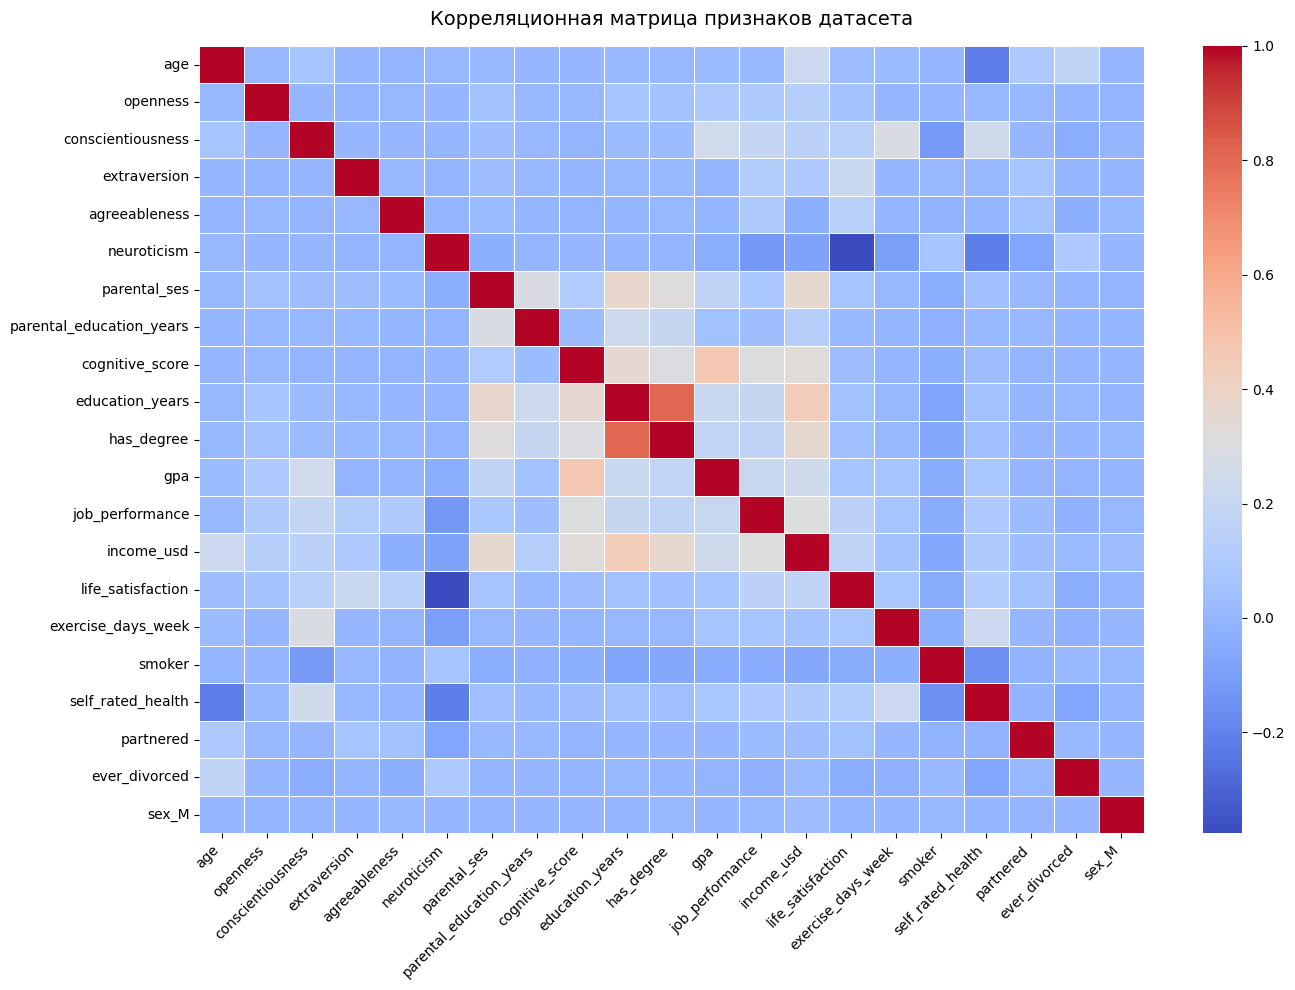

/tmp/ipykernel_604/1957050927.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, palette='Set2')


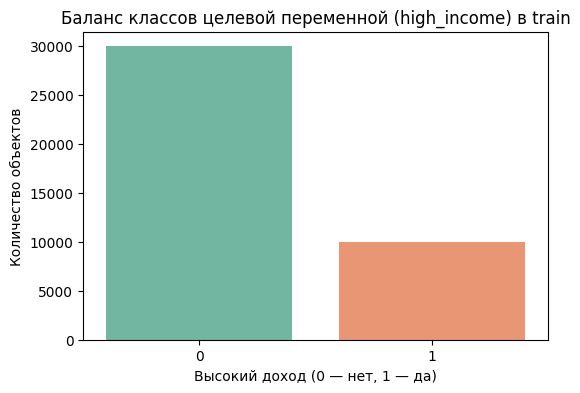

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#Основные статистические характеристики (среднее, ст. отклонение, мин, макс, квартили)
# Ограничимся выводом основных метрик для ключевых числовых колонок
stats_df = X_train.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
display(stats_df)

#Корреляционная матрица
plt.figure(figsize=(14, 10))
#корреляцию только для числовых столбцов тренировочной выборки
corr_matrix = X_train.select_dtypes(include=[np.number]).corr()

#тепловая карта
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title("Корреляционная матрица признаков датасета", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, palette='Set2')
plt.title("Баланс классов целевой переменной (high_income) в train")
plt.xlabel("Высокий доход (0 — нет, 1 — да)")
plt.ylabel("Количество объектов")
plt.show()

In [ ]:
#Разбор выбросов
print("Анализ выбросов методом межквартильного размаха (IQR) ")

continuous_cols = ['income_usd', 'gpa', 'age', 'cognitive_score', 'life_satisfaction']

for col in continuous_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_count = X_train[(X_train[col] < lower_bound) | (X_train[col] > upper_bound)].shape[0]
    print(f"Признак '{col}': найдено выбросов — {outliers_count} ({(outliers_count/len(X_train))*100:.2f}%)")


Анализ выбросов методом межквартильного размаха (IQR) 
Признак 'income_usd': найдено выбросов — 1237 (3.09%)
Признак 'gpa': найдено выбросов — 129 (0.32%)
Признак 'age': найдено выбросов — 137 (0.34%)
Признак 'cognitive_score': найдено выбросов — 287 (0.72%)
Признак 'life_satisfaction': найдено выбросов — 128 (0.32%)
Поскольку выбросы в признаках доходов (income_usd) и оценок отражают реальную дифференциацию в обществе (высокооплачиваемые специалисты, отличники), удалять их полностью нецелесообразно, чтобы не терять ценную информацию для классификации. Мы оставляем их в датасете.


In [ ]:
#Обработка пропущенных значений

# Считаем количество пропусков по каждому столбцу
missing_train = X_train.isnull().sum()
total_missing = missing_train.sum()

print(f"Общее количество пропусков в X_train: {total_missing}")

if total_missing > 0:
    print("\nСтолбцы с пропущенными значениями:")
    print(missing_train[missing_train > 0])
    print("\n Так как пропуски обнаружены, их необходимо обработать ")
else:
    print("\n Пропущенные значения в обучающей выборке полностью отсутствуют")

missing_test = X_test.isnull().sum().sum()
print(f"Общее количество пропусков в X_test: {missing_test}")

 Проверка пропущенных значений в обучающей выборке 
Общее количество пропусков в X_train: 0

 Пропущенные значения в обучающей выборке полностью отсутствуют. Дополнительная импутация (заполнение) не требуется.
Общее количество пропусков в X_test: 0


In [ ]:
#Обработка категориальных признаков
print("Обработка категориальных признаков ")

# Проверим какие колонки имеют тип 'object' (текстовые) в обучающей и тестовой выборках
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Найденные категориальные признаки: {categorical_cols}")

if len(categorical_cols) > 0:
    X_train_encoded = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True, dtype=int)
    X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True, dtype=int)

    X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

    print(f"Количество признаков после кодирования (в train): {X_train_encoded.shape[1]}")
else:
    X_train_encoded = X_train.copy()
    X_test_encoded = X_test.copy()
    print("\n Категориальных признаков для кодирования не обнаружено.")

Обработка категориальных признаков 
Найденные категориальные признаки: []

 Категориальных признаков для кодирования не обнаружено.


In [ ]:
from sklearn.preprocessing import StandardScaler

#Нормализация / стандартизация признаков

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train_encoded.columns, index=X_train_encoded.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test_encoded.columns, index=X_test_encoded.index)

print(f"Среднее значение первого признака после масштабирования в train: {X_train_scaled.iloc[:, 0].mean():.4f} (должно быть примерно 0)")
print(f"Стандартное отклонение первого признака: {X_train_scaled.iloc[:, 0].std():.4f} (должно быть примерно 1)")

Нормализация признаков (StandardScaler) 
Нормализация успешно выполнена!
Среднее значение первого признака после масштабирования в train: 0.0000 (должно быть ≈ 0)
Стандартное отклонение первого признака: 1.0000 (должно быть ≈ 1)


In [ ]:
from sklearn.linear_model import LogisticRegression

#Выбор модели и обучение

model = LogisticRegression(random_state=42, max_iter=1000)

model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print(f"Количество обученных коэффициентов (весов): {len(model.coef_[0])}")

 Обучение модели (Логистическая регрессия) 
Модель успешно обучена
Количество обученных коэффициентов (весов): 21


 Оценка качества модели на тестовой выборке 

Отчет о классификации (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7493
           1       1.00      1.00      1.00      2507

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000

ROC-AUC Score: 1.0000


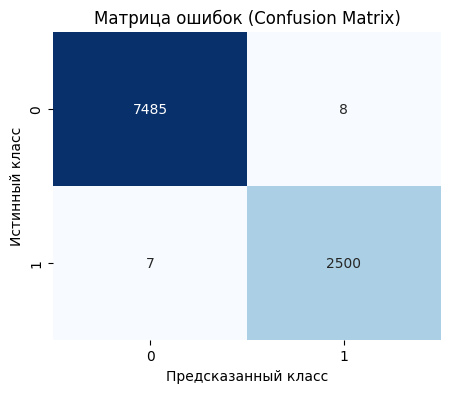

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# Оценка качества модели

y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print("\nОтчет о классификации:")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Матрица ошибок", fontsize=12)
plt.xlabel("Предсказанный класс", fontsize=10)
plt.ylabel("Истинный класс", fontsize=10)
plt.show()